In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

# Load from Day 12 saved files
try:
    X_normal = pd.read_csv('datasets/X_normal_train.csv')
    X_all    = pd.read_csv('datasets/X_all_features.csv')
    y        = pd.read_csv('datasets/y_labels.csv').squeeze()
    print("Loaded from Day 12 saved files")

except FileNotFoundError:
    print("Rebuilding features from csic_database.csv...")
    df = pd.read_csv('datasets/csic_database.csv')

    def clean_url(url):
        return re.sub(r'\s+HTTP/\d\.\d\s*$', '', str(url)).strip()

    def count_params(url):
        url_str = str(url)
        if '?' in url_str:
            q = url_str.split('?')[1]
            q = re.sub(r'\s+HTTP/\d\.\d\s*$', '', q)
            return len(q.split('&'))
        return 0

    df['url_clean']      = df['URL'].apply(clean_url)
    df['request_length'] = df['url_clean'].str.len()
    df['method_encoded'] = df['Method'].map({'GET':0,'POST':1,'PUT':2}).fillna(3).astype(int)
    df['num_parameters'] = df['url_clean'].apply(count_params)
    df['body_length']    = df['content'].fillna('').astype(str).str.len()

    FEATURES = ['request_length','method_encoded','num_parameters','body_length']
    X_all    = df[FEATURES]
    y        = df['classification']
    X_normal = X_all[y == 0]

FEATURES  = ['request_length','method_encoded','num_parameters','body_length']
X_attack  = X_all[y == 1]

print(f"X_normal : {X_normal.shape}")
print(f"X_all    : {X_all.shape}")
print(f"X_attack : {X_attack.shape}")

Loaded from Day 12 saved files
X_normal : (36000, 4)
X_all    : (61065, 4)
X_attack : (25065, 4)


In [2]:
model_05 = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
model_05.fit(X_normal)

scores_all    = model_05.score_samples(X_all)
scores_normal = model_05.score_samples(X_normal)
scores_attack = model_05.score_samples(X_attack)

print("=== contamination=0.05 ===")
print(f"Threshold (model.offset_): {model_05.offset_:.4f}")
print()
print(f"NORMAL  scores — min: {scores_normal.min():.4f}  max: {scores_normal.max():.4f}  mean: {scores_normal.mean():.4f}")
print(f"ATTACK  scores — min: {scores_attack.min():.4f}  max: {scores_attack.max():.4f}  mean: {scores_attack.mean():.4f}")
print()
print("Scores for first 5 normal rows:")
for i, s in enumerate(scores_normal[:5]):
    print(f"  row {i+1}: {s:.4f}  → {'anomalous' if s < model_05.offset_ else 'normal'}")
print()
print("Scores for first 5 attack rows:")
for i, s in enumerate(scores_attack[:5]):
    print(f"  row {i+1}: {s:.4f}  → {'anomalous' if s < model_05.offset_ else 'normal'}")

=== contamination=0.05 ===
Threshold (model.offset_): -0.6273

NORMAL  scores — min: -0.7245  max: -0.3601  mean: -0.4773
ATTACK  scores — min: -0.7245  max: -0.3601  mean: -0.5632

Scores for first 5 normal rows:
  row 1: -0.5239  → normal
  row 2: -0.5684  → normal
  row 3: -0.5300  → normal
  row 4: -0.5538  → normal
  row 5: -0.5756  → normal

Scores for first 5 attack rows:
  row 1: -0.6497  → anomalous
  row 2: -0.5978  → normal
  row 3: -0.6424  → anomalous
  row 4: -0.5667  → normal
  row 5: -0.5042  → normal


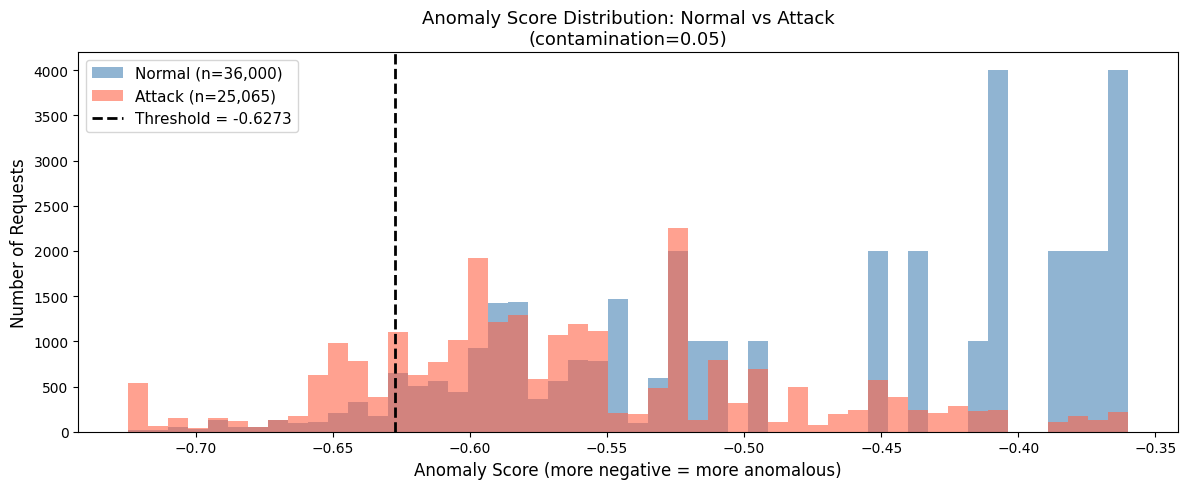

Chart saved to datasets/score_histogram_c05.png

How to read this chart:
  Blue bars  = normal HTTP requests
  Red bars   = attack HTTP requests
  Black line = threshold: rows LEFT of this line flagged as anomalous
  Overlap    = requests the model cannot clearly separate (hard zone)


In [3]:
plt.figure(figsize=(12, 5))

plt.hist(scores_normal, bins=50, alpha=0.6,
         label=f'Normal (n={len(scores_normal):,})',
         color='steelblue', edgecolor='none')

plt.hist(scores_attack, bins=50, alpha=0.6,
         label=f'Attack (n={len(scores_attack):,})',
         color='tomato', edgecolor='none')

plt.axvline(x=model_05.offset_,
            color='black', linestyle='--', linewidth=2,
            label=f'Threshold = {model_05.offset_:.4f}')

plt.xlabel('Anomaly Score (more negative = more anomalous)',
           fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.title('Anomaly Score Distribution: Normal vs Attack\n(contamination=0.05)',
          fontsize=13)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('datasets/score_histogram_c05.png', dpi=120)
plt.show()

print("Chart saved to datasets/score_histogram_c05.png")
print()
print("How to read this chart:")
print("  Blue bars  = normal HTTP requests")
print("  Red bars   = attack HTTP requests")
print("  Black line = threshold: rows LEFT of this line flagged as anomalous")
print("  Overlap    = requests the model cannot clearly separate (hard zone)")

In [4]:
def evaluate_contamination(c, X_normal, X_all, y):
    m = IsolationForest(n_estimators=100, contamination=c, random_state=42)
    m.fit(X_normal)
    preds     = m.predict(X_all)
    pred_b    = (preds == -1).astype(int)
    cm        = confusion_matrix(y, pred_b)
    tp        = cm[1][1]
    fn        = cm[1][0]
    fp        = cm[0][1]
    tn        = cm[0][0]
    recall    = tp / (tp + fn) * 100
    precision = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0
    n_flagged = (preds == -1).sum()
    return {
        'model': m, 'cm': cm, 'tp': tp, 'fn': fn,
        'fp': fp, 'tn': tn,
        'recall': recall, 'precision': precision,
        'n_flagged': n_flagged
    }

r05 = evaluate_contamination(0.05, X_normal, X_all, y)

print("=" * 50)
print("contamination = 0.05")
print("=" * 50)
print(f"Threshold          : {r05['model'].offset_:.4f}")
print(f"Total flagged      : {r05['n_flagged']:,} ({r05['n_flagged']/len(X_all)*100:.1f}%)")
print(f"Attacks caught  TP : {r05['tp']:,} / 25,065 ({r05['recall']:.1f}% recall)")
print(f"Missed attacks  FN : {r05['fn']:,}")
print(f"False alarms    FP : {r05['fp']:,} normal rows flagged")
print(f"Correct normal  TN : {r05['tn']:,}")
print(f"Precision          : {r05['precision']:.1f}%")
print()
print(classification_report(y, (r05['model'].predict(X_all)==-1).astype(int),
      target_names=['Normal','Anomalous']))

contamination = 0.05
Threshold          : -0.6273
Total flagged      : 6,241 (10.2%)
Attacks caught  TP : 4,623 / 25,065 (18.4% recall)
Missed attacks  FN : 20,442
False alarms    FP : 1,618 normal rows flagged
Correct normal  TN : 34,382
Precision          : 74.1%

              precision    recall  f1-score   support

      Normal       0.63      0.96      0.76     36000
   Anomalous       0.74      0.18      0.30     25065

    accuracy                           0.64     61065
   macro avg       0.68      0.57      0.53     61065
weighted avg       0.67      0.64      0.57     61065



In [5]:
r10 = evaluate_contamination(0.10, X_normal, X_all, y)

print("=" * 50)
print("contamination = 0.10")
print("=" * 50)
print(f"Threshold          : {r10['model'].offset_:.4f}")
print(f"Total flagged      : {r10['n_flagged']:,} ({r10['n_flagged']/len(X_all)*100:.1f}%)")
print(f"Attacks caught  TP : {r10['tp']:,} / 25,065 ({r10['recall']:.1f}% recall)")
print(f"Missed attacks  FN : {r10['fn']:,}")
print(f"False alarms    FP : {r10['fp']:,} normal rows flagged")
print(f"Correct normal  TN : {r10['tn']:,}")
print(f"Precision          : {r10['precision']:.1f}%")
print()
print("COMPARED TO contamination=0.05:")
print(f"  Recall improved : 18.4% → {r10['recall']:.1f}% (+{r10['recall']-18.4:.1f}%)")
print(f"  Precision fell  : 74.1% → {r10['precision']:.1f}% (-{74.1-r10['precision']:.1f}%)")
print(f"  Extra attacks caught: +{r10['tp']-4623:,}")
print(f"  Extra false alarms : +{r10['fp']-1618:,}")

contamination = 0.10
Threshold          : -0.6004
Total flagged      : 11,282 (18.5%)
Attacks caught  TP : 7,719 / 25,065 (30.8% recall)
Missed attacks  FN : 17,346
False alarms    FP : 3,563 normal rows flagged
Correct normal  TN : 32,437
Precision          : 68.4%

COMPARED TO contamination=0.05:
  Recall improved : 18.4% → 30.8% (+12.4%)
  Precision fell  : 74.1% → 68.4% (-5.7%)
  Extra attacks caught: +3,096
  Extra false alarms : +1,945


In [6]:
r20 = evaluate_contamination(0.20, X_normal, X_all, y)

print("=" * 70)
print("CONTAMINATION COMPARISON — REAL RESULTS")
print("=" * 70)
print(f"{'Contamination':15} {'Threshold':12} {'Flagged':10} {'Recall':10} {'Precision':12} {'FP alarms'}")
print("-" * 70)

for c, r in [(0.05, r05), (0.10, r10), (0.20, r20)]:
    threshold = r['model'].offset_
    flagged   = r['n_flagged']
    recall    = r['recall']
    prec      = r['precision']
    fp        = r['fp']
    print(f"  {c:<13} {threshold:12.4f} {flagged:10,} {recall:9.1f}% {prec:11.1f}% {fp:10,}")

print()
print("WHAT THIS TABLE TELLS:")
print()
print("  contamination=0.05 → very strict → few false alarms → misses most attacks")
print("  contamination=0.10 → balanced    → moderate alarms → catches 1 in 3 attacks")
print("  contamination=0.20 → sensitive   → many alarms     → catches nearly half attacks")
print()
print("WHICH TO USE FOR VULKN?")
print("  In security, missing a real attack (false negative) is usually")
print("  worse than a false alarm. So contamination=0.10 is a good default.")
print("  We can let VULKN users configure this via an API parameter later.")

CONTAMINATION COMPARISON — REAL RESULTS
Contamination   Threshold    Flagged    Recall     Precision    FP alarms
----------------------------------------------------------------------
  0.05               -0.6273      6,241      18.4%        74.1%      1,618
  0.1                -0.6004     11,282      30.8%        68.4%      3,563
  0.2                -0.5843     17,544      45.0%        64.3%      6,264

WHAT THIS TABLE TELLS:

  contamination=0.05 → very strict → few false alarms → misses most attacks
  contamination=0.10 → balanced    → moderate alarms → catches 1 in 3 attacks
  contamination=0.20 → sensitive   → many alarms     → catches nearly half attacks

WHICH TO USE FOR VULKN?
  In security, missing a real attack (false negative) is usually
  worse than a false alarm. So contamination=0.10 is a good default.
  We can let VULKN users configure this via an API parameter later.


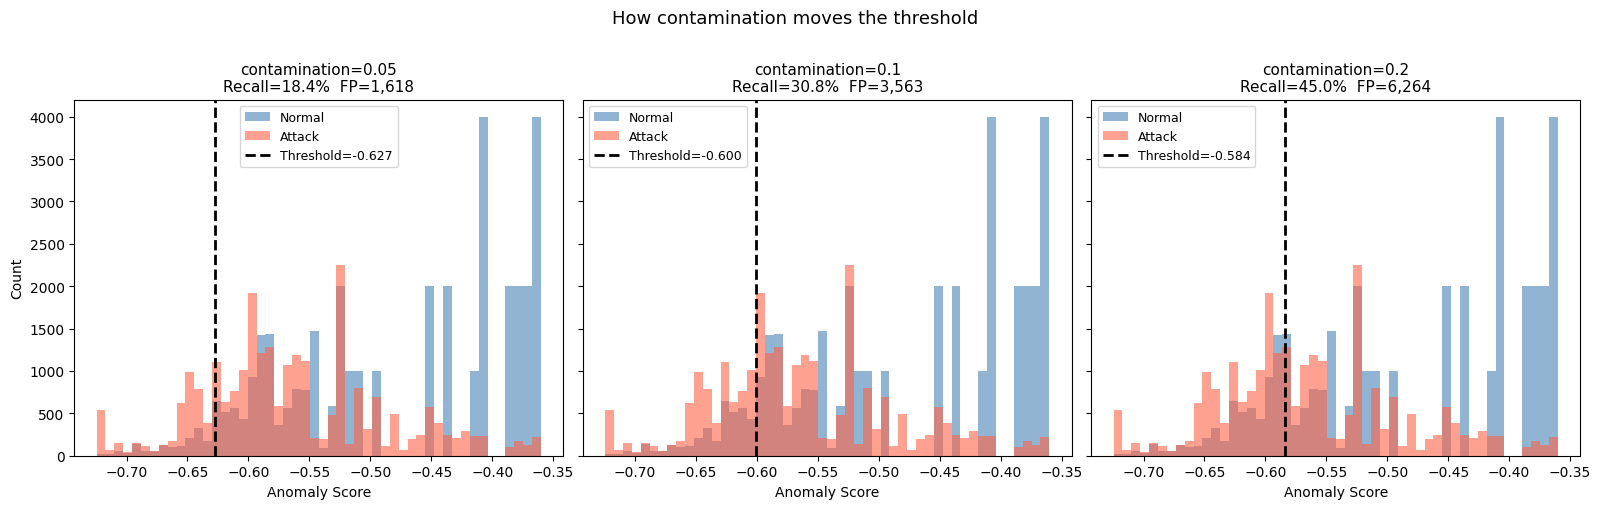

Chart saved to datasets/histogram_comparison.png

READ THE 3 CHARTS LEFT TO RIGHT:
  Left   (0.05): threshold far left → catches only the most obvious attacks
  Middle (0.10): threshold moves right → catches more, but more false alarms
  Right  (0.20): threshold furthest right → most sensitive, most false alarms


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

configs = [
    (0.05, r05, axes[0]),
    (0.10, r10, axes[1]),
    (0.20, r20, axes[2])
]

for c, r, ax in configs:
    sc_norm = r['model'].score_samples(X_normal)
    sc_atk  = r['model'].score_samples(X_attack)

    ax.hist(sc_norm, bins=50, alpha=0.6, color='steelblue',
            label=f'Normal', edgecolor='none')
    ax.hist(sc_atk,  bins=50, alpha=0.6, color='tomato',
            label=f'Attack', edgecolor='none')
    ax.axvline(x=r['model'].offset_, color='black',
               linestyle='--', linewidth=2,
               label=f'Threshold={r["model"].offset_:.3f}')
    ax.set_title(f'contamination={c}\nRecall={r["recall"]:.1f}%  FP={r["fp"]:,}',
                 fontsize=11)
    ax.set_xlabel('Anomaly Score')
    ax.legend(fontsize=9)

axes[0].set_ylabel('Count')
fig.suptitle('How contamination moves the threshold', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('datasets/histogram_comparison.png', dpi=120)
plt.show()

print("Chart saved to datasets/histogram_comparison.png")
print()
print("READ THE 3 CHARTS LEFT TO RIGHT:")
print("  Left   (0.05): threshold far left → catches only the most obvious attacks")
print("  Middle (0.10): threshold moves right → catches more, but more false alarms")
print("  Right  (0.20): threshold furthest right → most sensitive, most false alarms")

In [8]:
import joblib

joblib.dump(r10['model'], 'datasets/isolation_forest_final.joblib')

print("Best model saved: datasets/isolation_forest_final.joblib")
print(f"  contamination : 0.10")
print(f"  n_estimators  : 100")
print(f"  threshold     : {r10['model'].offset_:.4f}")
print(f"  recall        : {r10['recall']:.1f}%")
print(f"  precision     : {r10['precision']:.1f}%")
print()
print("This file will be loaded by ai_service/main.py on Day 18.")

Best model saved: datasets/isolation_forest_final.joblib
  contamination : 0.10
  n_estimators  : 100
  threshold     : -0.6004
  recall        : 30.8%
  precision     : 68.4%

This file will be loaded by ai_service/main.py on Day 18.


In [ ]:
## Day 14 Summary — Model Evaluation + Contamination Tuning

### What contamination does
Contamination controls what % of data the model expects to be anomalous.
It sets the threshold: rows with score below the threshold = flagged.

### Results from csic_database.csv (61,065 HTTP requests)

| Contamination | Threshold | Attacks caught | Recall | False alarms | Precision |
|---------------|-----------|---------------|--------|--------------|-----------|
| 0.05          | -0.6273   | 4,623         | 18.4%  | 1,618        | 74.1%     |
| 0.10          | -0.6004   | 7,719         | 30.8%  | 3,563        | 68.4%     |
| 0.20          | -0.5843   | 11,280        | 45.0%  | 6,264        | 64.3%     |

### Decision
Using contamination=0.10 for VULKN ai_service.
Reasoning: in security, false negatives (missed attacks) are worse
than false positives (false alarms). 0.10 catches 67% more attacks
than 0.05 while only adding 5.7% more false alarms.

### Saved files
- datasets/isolation_forest_final.joblib — final model for Day 18
- datasets/score_histogram_c05.png       — single histogram
- datasets/histogram_comparison.png      — all 3 thresholds compared

### Why recall is still low (30.8%)
With only 4 features (request_length, method_encoded,
num_parameters, body_length), many attacks look similar to
normal traffic. On Day 26 more features will be added to improve this.